In [1]:
import numpy as np
import pandas as pd 

import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns

import warnings  # suppress warnings 
warnings.filterwarnings('ignore')

from itertools import cycle
cycol = cycle('gbmrc')  # for colors

In [194]:
# read csv
c1 = pd.read_csv("World_Development_Indicators_2\world_bank_data.csv")
c2 = pd.read_csv("World_Development_Indicators_3\world_bank_data.csv")
countries = c1.merge(c2, how="outer", sort=False) 

# data cleaning
countries_dict = {}
def get_country_data(country_name: str):
    result = countries[countries["Country Name"] == country_name].drop(columns = ["Country Name", "Country Code", "Series Code"])
    if result.size > 0: 
        result = result.transpose()      # flip the table 
        result.columns = result.iloc[0]  # set columns to data variables 
        result = result[1:]
        result.index = pd.to_numeric(result.index.str[:4])  # alter the index (years) to yyyy format
        for col in result.columns:
            result[col] = pd.to_numeric(result[col], errors='coerce')   # convert everything from dtype 'object' to numeric 
        countries_dict[country_name] = result
        return result
    else:
        print("Invalid argument: ", country_name)
        return -1

# get data 
world = get_country_data("World")
united_states = get_country_data("United States")
japan = get_country_data("Japan")
china = get_country_data("China")
india = get_country_data("India")
low_income = get_country_data("Low income")
middle_income = get_country_data("Middle income")
high_income = get_country_data("High income")


In [3]:
def standardize(data):
    mean = data.mean()
    std = data.std()
    
    if std == 0:
        raise ValueError("Standard deviation is zero. Data cannot be standardized.")  # prevent divide by 0 error 
    
    return (data - mean) / std

In [192]:
# creates a plot for all avalible countries 
# fplot (function) - the function used to plot (eg. plot_population_ages)
def plot_all(fplot, title: str):
    plt.figure(figsize=(10, 18))
    count = 1
    for country_name in countries_dict:
        plt.subplot(4, 2, count)
        count += 1
        fplot(countries_dict[country_name][:])    # change this part to show a different relationship 
        plt.title(country_name)
    
    plt.suptitle(title+"\n")
    plt.tight_layout()  
    plt.show()

In [188]:
# create population demography plots
def plot_population_ages(data):
    data = data[["Population ages 0-14, total", "Population ages 15-64, total", "Population ages 65 and above, total"]] / 1000000 # population in millions
    sns.lineplot(data)
    plt.ylim(0, data.max().max()+20)
    plt.xlabel("Year") 
    plt.ylabel("Population (millions)") 
    plt.legend(title="Demographic Groups", loc="upper left", prop={'size': 8})

In [190]:
def plot_population_labor(data, title: str):
    plt.figure(figsize=(10, 3))
    color="b"
    color2="r"
    
    plt.subplot(1, 3, 1)
    sns.lineplot(data["Population growth (annual %)"], color = color)
    plt.xlim(1960, 2023)
    plt.xlabel("Year") 
    plt.ylabel("Population growth") 
    plt.title("% Population growth over time") 

    plt.subplot(1, 3, 2)
    sns.lineplot(data["Labor force participation rate, total (% of total population ages 15+) (national estimate)"], color = color2)
    plt.xlim(1960, 2023)
    plt.xlabel("Year") 
    plt.ylabel("Labor force participation rate") 
    plt.title(" % Labor force participation rate over time")
    
    plt.subplot(1, 3, 3)
    # sns.regplot(x= standardize(data["Labor force participation rate, total (% of total population ages 15+) (national estimate)"]), y=standardize(data["Population growth (annual %)"]), color = color)
    sns.lineplot(standardize(data["Labor force participation rate, total (% of total population ages 15+) (national estimate)"]), label = "Labor force", color = color2)
    sns.lineplot(standardize(data["Population growth (annual %)"]), label = "Population growth",color = color)
    plt.legend(loc="upper right", prop={'size': 7})
    plt.xlabel("Year") 
    plt.ylabel("Z-score") 
    plt.title("Correlation") 

    plt.suptitle(title)
    plt.tight_layout()  
    plt.show()

In [204]:
# functions for relationships with dependency ratio vs economic factors

def get_dependency_ratio(data):
    data["Num dependents"] = data["Population ages 0-14, total"] + data["Population ages 65 and above, total"]
    data["Dependency ratio"] = data["Num dependents"] / data["Population ages 15-64, total"]
    return data

def plot_dependency_ratio(data):
    data = get_dependency_ratio(data)
    sns.lineplot(data["Dependency ratio"], color=next(cycol))

def plot_dependency_exports(data):
    data = get_dependency_ratio(data)
    data["Exports of goods and services"] = data["GDP (current US$)"] * (data["Exports of goods and services (% of GDP)"] / 100)
    sns.regplot(x=data["Dependency ratio"], y=data["Exports of goods and services"], color=next(cycol))

def plot_dependency_exports_percentage(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Exports of goods and services (% of GDP)"], color=next(cycol))

def plot_dependency_net_exports(data):
    data = get_dependency_ratio(data)
    data["Exports of goods and services"] = data["GDP (current US$)"] * (data["Exports of goods and services (% of GDP)"] / 100)
    data["Imports of goods and services"] = data["GDP (current US$)"] * (data["Imports of goods and services (% of GDP)"] / 100)
    data["Net exports of goods and services"] = data["Exports of goods and services"] - data["Imports of goods and services"]    
    sns.regplot(x=data["Dependency ratio"], y=data["Net exports of goods and services"], color=next(cycol))

def plot_dependency_imports(data):
    data = get_dependency_ratio(data)
    data["Imports of goods and services"] = data["GDP (current US$)"] * (data["Imports of goods and services (% of GDP)"] / 100)
    sns.regplot(x=data["Dependency ratio"], y=data["Imports of goods and services"], color=next(cycol))

def plot_dependency_imports_percentage(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Imports of goods and services (% of GDP)"], color=next(cycol))

def plot_dependency_net_imports(data):
    data = get_dependency_ratio(data)
    data["Exports of goods and services"] = data["GDP (current US$)"] * (data["Exports of goods and services (% of GDP)"] / 100)
    data["Imports of goods and services"] = data["GDP (current US$)"] * (data["Imports of goods and services (% of GDP)"] / 100)
    data["Net imports of goods and services"] = data["Imports of goods and services"] - data["Exports of goods and services"]    
    sns.regplot(x=data["Dependency ratio"], y=data["Net imports of goods and services"], color=next(cycol))
    
def plot_dependency_gdp(data):
    data = get_dependency_ratio(data)
    sns.lineplot( standardize(data["GDP (current US$)"]), label = "GDP (current US$)", color="r")
    sns.lineplot( -standardize(data["Dependency ratio"]), label = "Dependency ratio (inverted)", color="b")

def plot_dependency_savings(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Gross domestic savings (% of GDP)"], color=next(cycol))

def plot_dependency_consumption(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Final consumption expenditure (% of GDP)"], color=next(cycol))

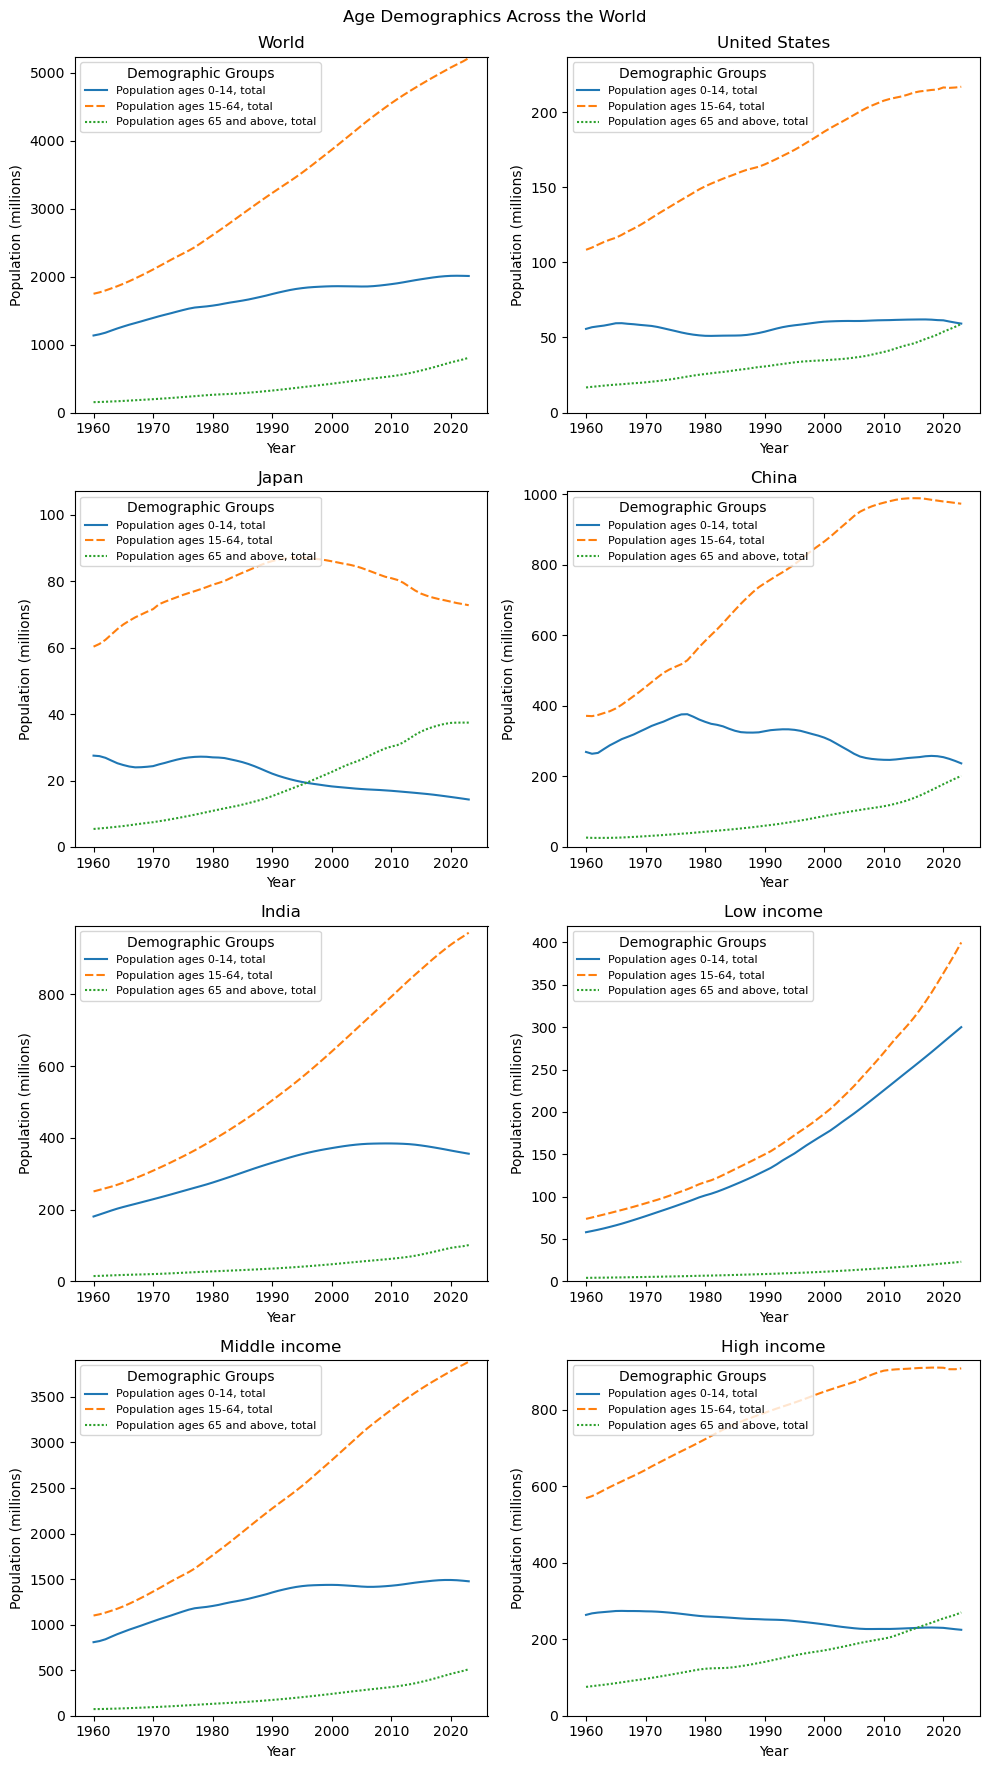

In [196]:
plot_all(plot_population_ages, "Age Demographics Across the World")

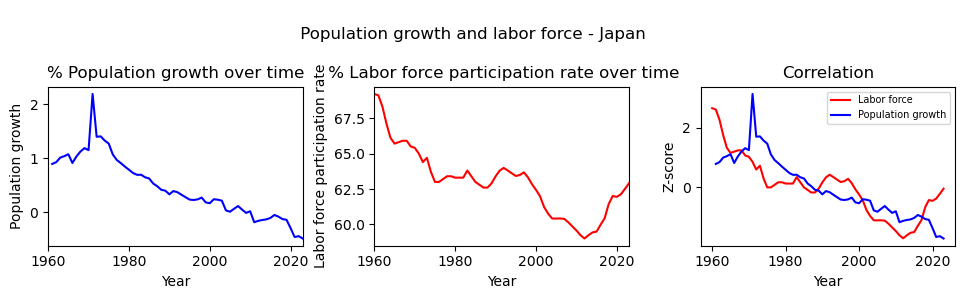

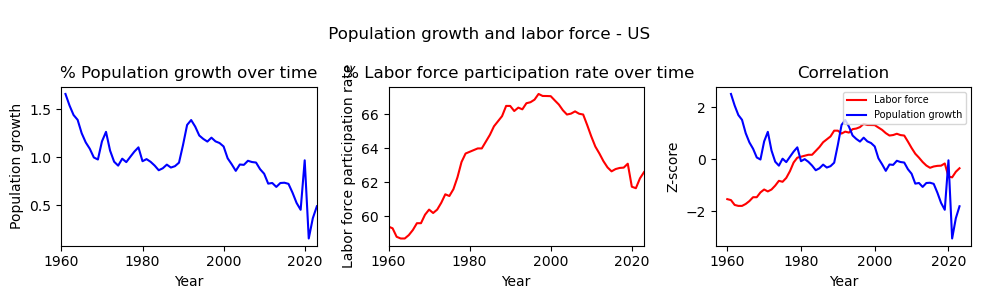

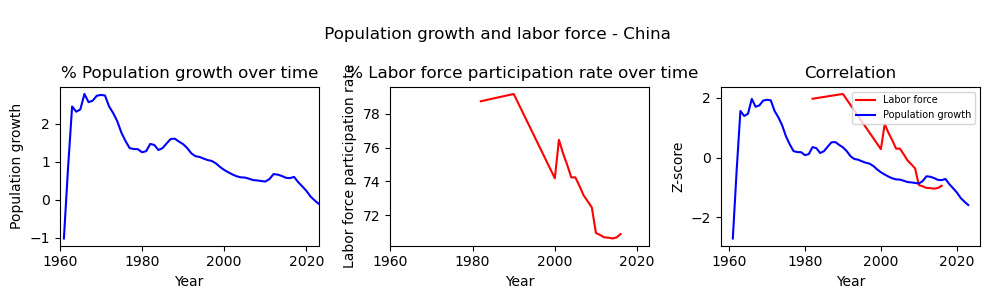

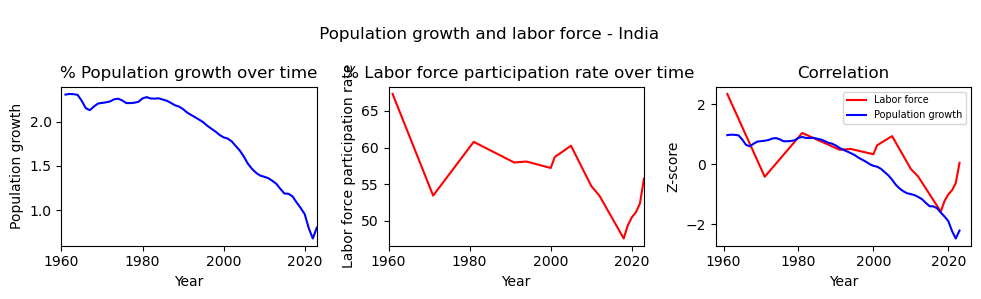

In [197]:
# plot graphs 
plot_population_labor(japan[:], "\n Population growth and labor force - Japan")
plot_population_labor(united_states[:], "\n Population growth and labor force - US")
plot_population_labor(china[:], "\n Population growth and labor force - China")
plot_population_labor(india[:], "\n Population growth and labor force - India")

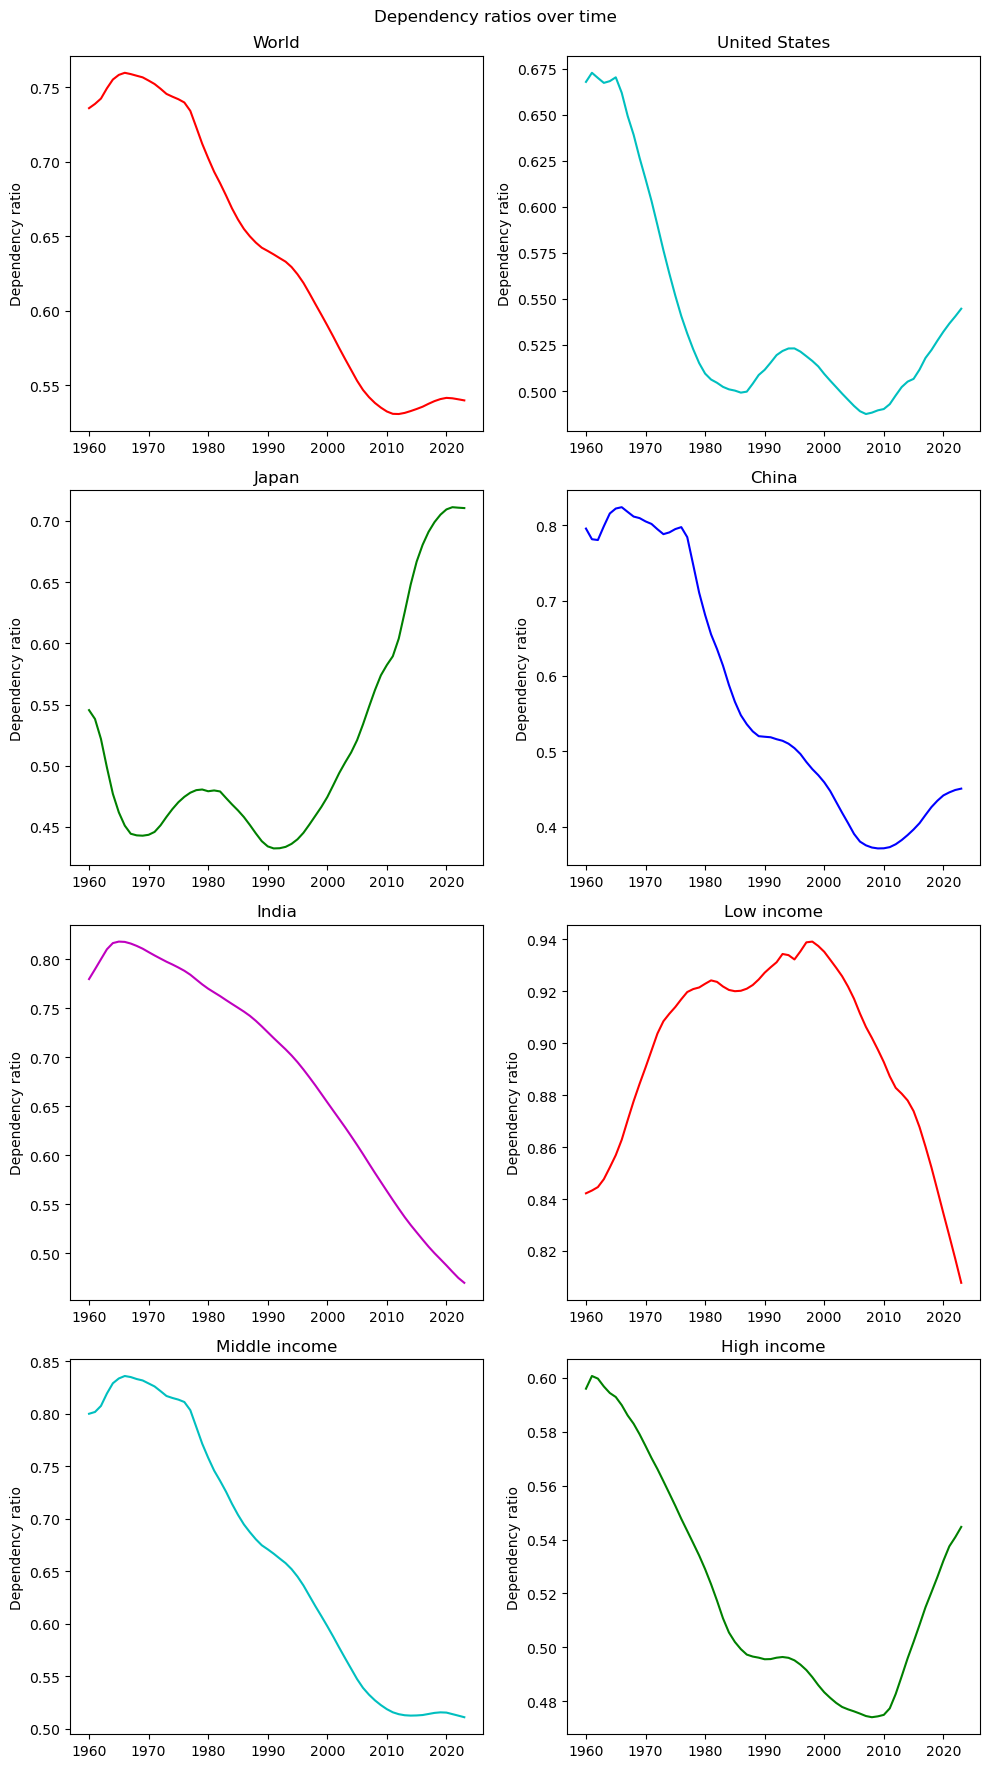

In [186]:
plot_all(plot_dependency_ratio, "Dependency ratios over time")

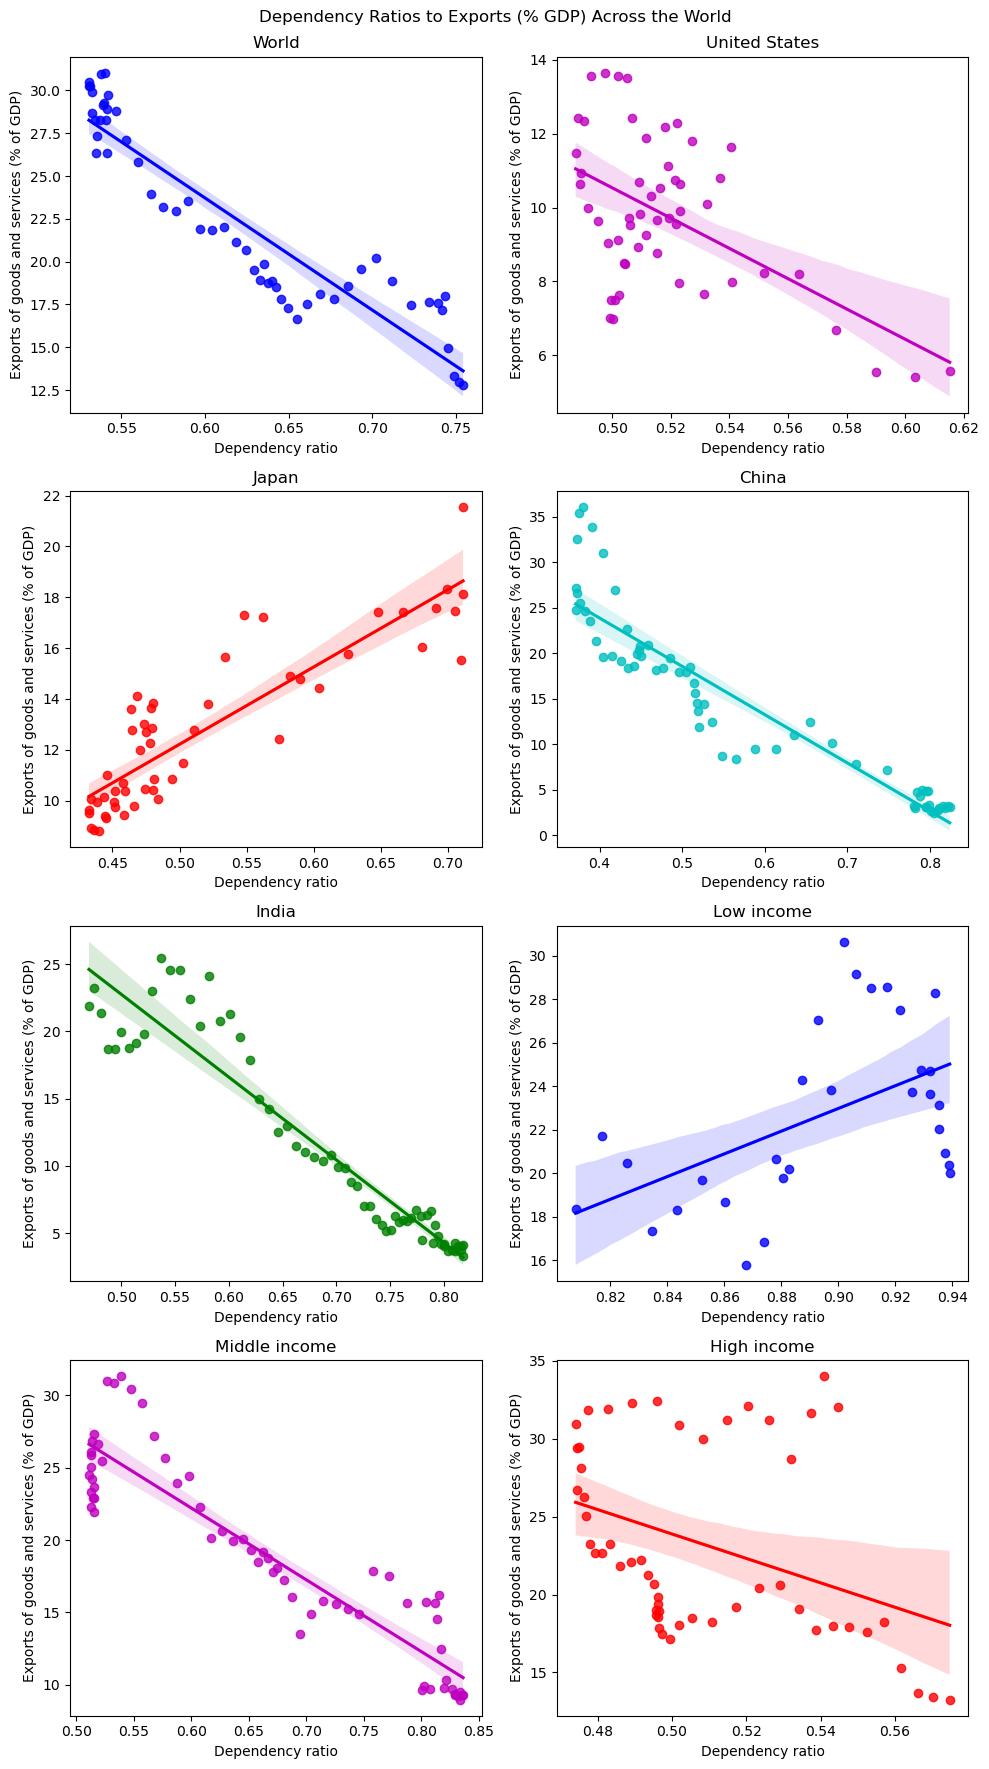

In [200]:
plot_all(plot_dependency_exports_percentage, "Dependency Ratios to Exports (% GDP) Across the World")

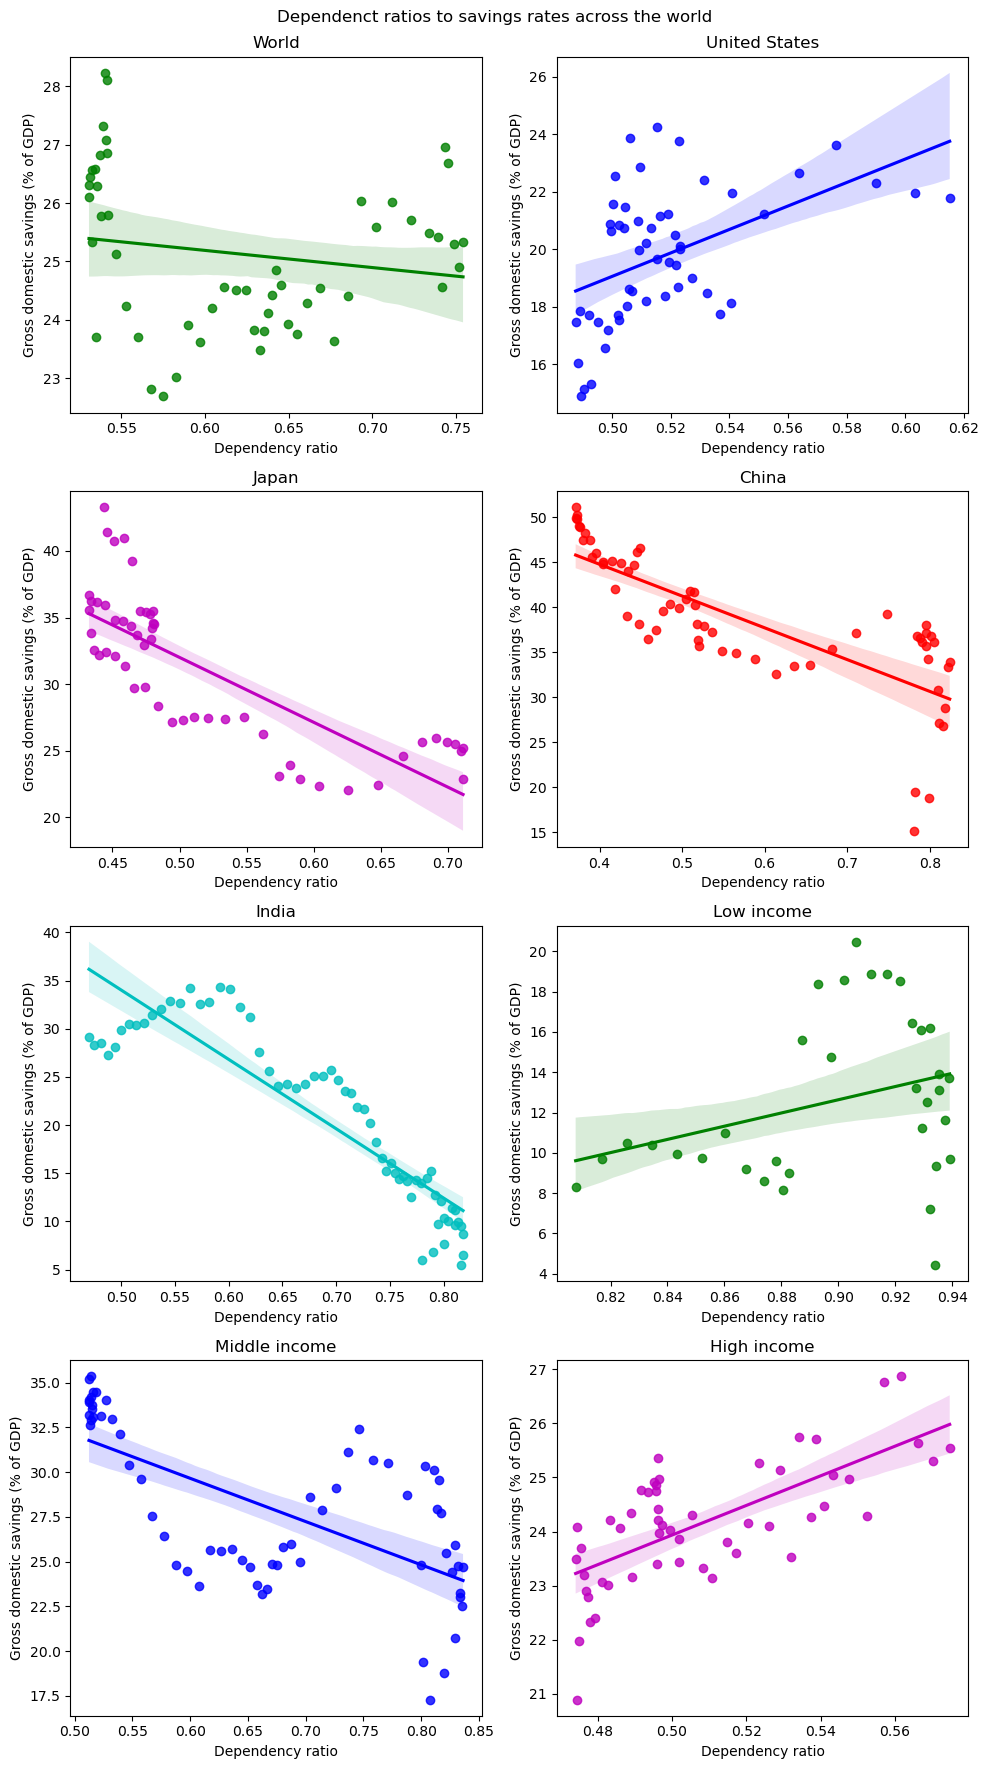

In [212]:
# create graphs
plot_all(plot_dependency_savings, "Dependenct ratios to savings rates across the world")